In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import numpy as np

def visualize_patch_matching(target_matrix, patch_idx=98, title='Crop2 → Crop1 Matching'):
    """
    Visualize the soft matching region in crop1 for a specific patch in crop2.

    Args:
        target_matrix (Tensor or np.array): shape [196, 196]
        patch_idx (int): index in crop2 (0~195)
    """
    if isinstance(target_matrix, torch.Tensor):
        target_matrix = target_matrix.numpy()

    heatmap = target_matrix[patch_idx].reshape(14, 14)

    plt.figure(figsize=(5, 5))
    plt.imshow(heatmap, cmap='hot', interpolation='nearest')
    plt.title(f"{title} (Patch {patch_idx})")
    plt.colorbar(label='Matching Weight')
    plt.axis('off')
    plt.show()

def gaussian_kernel_normalized(size, sigma=1):
    """Generates a (size x size) Gaussian kernel with mean 0 and standard deviation sigma,
    normalized so that the center value is 1."""
    x, y = np.mgrid[-size//2 + 1:size//2 + 1, -size//2 + 1:size//2 + 1]
    g = np.exp(-((x**2 + y**2) / (2.0 * sigma**2)))
    g = g / g.sum()  # Normalize to sum to 1
    g = g / g[size//2, size//2]  # Normalize so the center value is 1
    return g


def get_one2one_patch_matching_target_fixed14(idx1_pair, idx2_pair):
    """
    For crop1 and crop2 (both 14x14), generate a soft one-to-one matching matrix [196, 196],
    where each patch in crop2 corresponds to a soft region in crop1 using a 5x5 Gaussian kernel.
    """
    crop_size = 14
    gaussian = gaussian_kernel_normalized(5)  # [5, 5]
    half_k = 2

    target_matrix = torch.zeros(crop_size**2, crop_size**2)

    for i in range(crop_size):
        for j in range(crop_size):
            # Absolute position in full grid
            gx2, gy2 = idx2_pair[0] + i, idx2_pair[1] + j

            # Center of kernel in crop1 coordinate
            gx1_center = gx2 - idx1_pair[0]
            gy1_center = gy2 - idx1_pair[1]

            idx_crop2 = i * crop_size + j

            for dx in range(-half_k, half_k + 1):
                for dy in range(-half_k, half_k + 1):
                    ni = gx1_center + dx
                    nj = gy1_center + dy

                    if 0 <= ni < crop_size and 0 <= nj < crop_size:
                        idx_crop1 = ni * crop_size + nj
                        target_matrix[idx_crop2, idx_crop1] = gaussian[dx + half_k, dy + half_k]

    return target_matrix  # [196, 196]


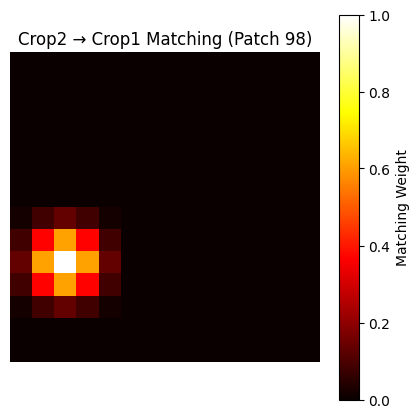

In [2]:
idx1_pair = (10, 10)
idx2_pair = (12, 12)
target_matrix = get_one2one_patch_matching_target_fixed14(idx1_pair, idx2_pair)

# 可视化 crop2 中间位置 patch（第98个）在 crop1 中的匹配区域
visualize_patch_matching(target_matrix, patch_idx=98)

In [1]:
import numpy as np

def gaussian_kernel_normalized(size, sigma=1):
    """Generates a (size x size) Gaussian kernel with mean 0 and standard deviation sigma,
    normalized so that the center value is 1."""
    x, y = np.mgrid[-size//2 + 1:size//2 + 1, -size//2 + 1:size//2 + 1]
    g = np.exp(-((x**2 + y**2) / (2.0 * sigma**2)))
    g = g / g.sum()  # Normalize to sum to 1
    g = g / g[size//2, size//2]  # Normalize so the center value is 1
    return g

g = gaussian_kernel_normalized(5)
print(g)

[[0.01831564 0.082085   0.13533528 0.082085   0.01831564]
 [0.082085   0.36787944 0.60653066 0.36787944 0.082085  ]
 [0.13533528 0.60653066 1.         0.60653066 0.13533528]
 [0.082085   0.36787944 0.60653066 0.36787944 0.082085  ]
 [0.01831564 0.082085   0.13533528 0.082085   0.01831564]]
